**Eye-Tracking & Neurocognitive Intelligence | Reading Comprehension & Neurocognitive Modelling | Presented by: Reza Saadatyar (2026)**

**04 | Sequential Modelling and Gaze–Text Fusion**

![Sequential Modelling and Gaze–Text Fusion — scientific workflow](../../images/04_sequential_and_multimodal_models.svg)

**Objective:** Compare masked CNN, GRU and Transformer fixation-sequence models with a text-only MLP and gaze–text fusion.

**Dataset:** Trial-level features and the local aligned fixation sequence cache from Notebook 02.

**Scope:** Compare ordered-fixation encoders and static text predictors, selecting checkpoints on Validation without scoring Test outcomes.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("reading_comprehension_modelling")

# ---------------------------- 2. Standard Library ----------------------------
import sys

# --------------------------- 3. Study Dependencies ---------------------------
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r",
     str(root / "reading_comprehension_modelling" / "requirements.txt")],
    check=True,
)

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 5. Machine Learning and Deep Learning -------------------
import torch
from reading_models import neural_predictions, NEURAL
from reading_evaluation import metric

# ------------------- 6. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

# ----------------- 7. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from core.computer_device import computer_device
from onestop_io import validate_splits, validate_trial_index
from reading_features import load_sequences

# ----------------------------- 8. Compute Device -----------------------------
device = computer_device(min_vram_gb=None)

# ------------------- 9. Output Directory and Setup Summary -------------------
out_dir = root / "reading_comprehension_modelling" / "output"
out_dir.mkdir(parents=True, exist_ok=True)
processed = root / "data" / "processed" / "onestop"
processed.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)
print("Study outputs:", out_dir)
print("Local data directory:", processed)
print("Python:", sys.version.split()[0])


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Study outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/reading_comprehension_modelling/output
Local data directory: /content/Eye-Tracking-Neurocognitive-Intelligence/data/processed/onestop
Python: 3.13.16


**02. Reconcile Ordered Fixation Sequences**

Load the trial feature table, participant assignments and local fixation-sequence cache. The sequence reader checks trial order, array dimensions, finite values and valid-position masks. The input array has shape `(9718, 256, 4)`. Padding is excluded from Training scaling and sequence pooling.

In [3]:
# ================= 02. Reconcile Ordered Fixation Sequences ==================

# ------------------- 1. Load and Reconcile Trial Features --------------------
identity = ["trial_id","participant_id","trial_index","article_batch",
            "article_key","paragraph_key","question_key","difficulty_level"]
table = pd.read_csv(out_dir/"02_trial_features.csv",dtype={c:str for c in identity})
index = pd.read_csv(out_dir/"01_trial_index.csv",dtype=str)
index["is_correct"] = index.is_correct.astype(int)
validate_trial_index(index,table)

# ------------------------- 2. Load Participant Roles -------------------------
splits = pd.read_csv(out_dir/"01_participant_splits.csv",dtype=str)
validate_splits(table,splits)

# -------------------- 3. Load Aligned Fixation Sequences ---------------------
x,mask = load_sequences(processed/"02_fixation_sequences.npz",table)
print("Sequence candidates:",NEURAL)
print("Sequence shape:",x.shape)


Sequence candidates: ['mlp_text', 'cnn_gaze', 'cnn_fusion', 'gru_gaze', 'gru_fusion', 'transformer_gaze', 'transformer_fusion']
Sequence shape: (9718, 256, 4)


**03. Train Sequence and Gaze–Text Models**

Compare masked 1D CNN, GRU and two-layer Transformer gaze encoders, each with gaze-only and gaze–text fusion variants. A text-only MLP supplies the seventh neural comparator. Text inputs are static paragraph features rather than TF-IDF vectors.

Train with AdamW (learning rate 0.001, weight decay 0.0001), weighted binary cross-entropy, batch size 64 and seed 17. Use a fixed threshold of 0.5 and retain the earliest epoch achieving maximum Validation Macro F1, with a limit of 15 epochs and patience three.

The 14 candidate–protocol fits use an NVIDIA Tesla T4 (PyTorch 2.14.1+cu130, CUDA 13.0, Python 3.13.16). Training lasts 4–15 epochs, with 13 configurations stopping before the epoch limit. Protocol B GRU gaze reaches the limit. The prediction table contains 58,954 scores and the training history contains 133 epoch records.

In [4]:
# ================== 03. Train Sequence and Gaze–Text Models ==================

# --------------------- 1. Fit Fixed Sequence Candidates ----------------------
neural, history, configs = neural_predictions(table,splits,x,mask,seed=17,epochs=15,patience=3)

# ------------------- 2. Summarise Model Training Evidence --------------------
print("Prediction rows:",len(neural))
display(history.tail())


Device: cuda
A_unseen_people mlp_text Validation macro F1: 0.5075
A_unseen_people cnn_gaze Validation macro F1: 0.518
A_unseen_people cnn_fusion Validation macro F1: 0.5125
A_unseen_people gru_gaze Validation macro F1: 0.5251
A_unseen_people gru_fusion Validation macro F1: 0.5204


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/NestedTensorImpl.cpp:177.)
  output = torch._nested_tensor_from_mask(


A_unseen_people transformer_gaze Validation macro F1: 0.5202
A_unseen_people transformer_fusion Validation macro F1: 0.5075
B_unseen_batch mlp_text Validation macro F1: 0.5308
B_unseen_batch cnn_gaze Validation macro F1: 0.5281
B_unseen_batch cnn_fusion Validation macro F1: 0.5226
B_unseen_batch gru_gaze Validation macro F1: 0.5358
B_unseen_batch gru_fusion Validation macro F1: 0.5263
B_unseen_batch transformer_gaze Validation macro F1: 0.5296
B_unseen_batch transformer_fusion Validation macro F1: 0.5458
Prediction rows: 58954


,protocol,model,epoch,train_loss,validation_macro_f1
128,B_unseen_batch,transformer_fusion,2,0.257465,0.535172
129,B_unseen_batch,transformer_fusion,3,0.256876,0.545760
130,B_unseen_batch,transformer_fusion,4,0.256537,0.528948
131,B_unseen_batch,transformer_fusion,5,0.256500,0.528152
132,B_unseen_batch,transformer_fusion,6,0.255855,0.522671


**04. Inspect Validation Learning Curves**

The learning curves show Validation Macro F1 for each candidate and protocol over the actual training epochs. The highest neural Validation Macro F1 is 0.5251 for GRU gaze in A (epoch 10) and 0.5458 for Transformer fusion in B (epoch 3). Both are below their respective classical Validation leaders (0.5571 and 0.5702).

Fusion minus the corresponding gaze-only encoder changes Macro F1 by −0.0055, −0.0046 and −0.0127 in A, and −0.0056, −0.0095 and +0.0161 in B, for CNN, GRU and Transformer respectively. These are descriptive differences, not uncertainty-adjusted effects or evidence of unseen-article generalisation. The classical lexical and neural static-text representations differ, so the comparisons do not isolate architecture or temporal ordering alone. Test metrics are calculated in Notebook 05.

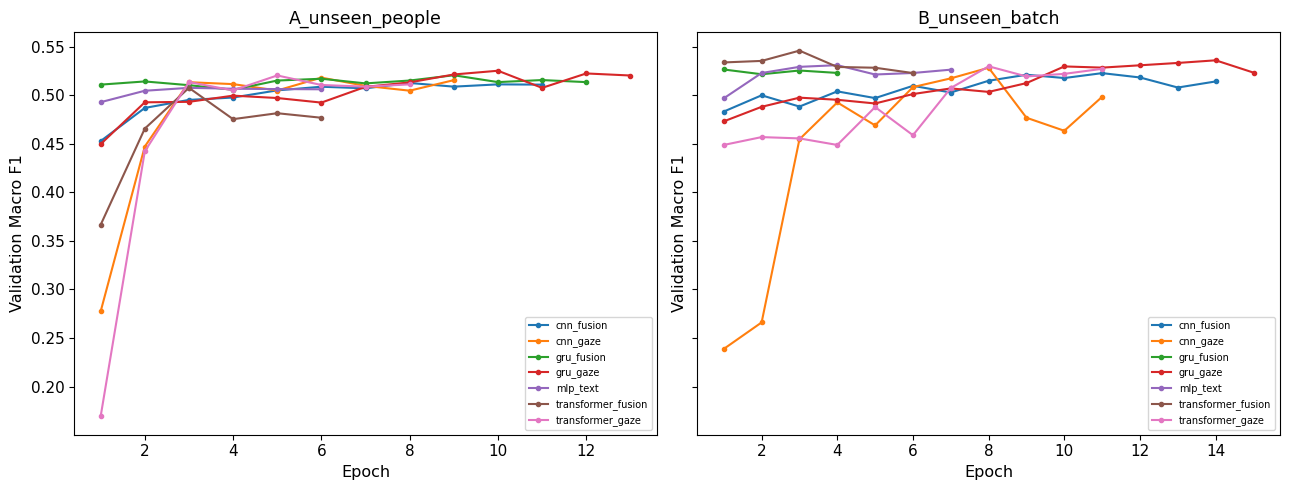

,protocol,model,n_trials,accuracy,macro_f1,balanced_accuracy,auroc,incorrect_auprc,incorrect_precision,incorrect_recall,brier
3,A_unseen_people,gru_gaze,1943,0.715389,0.525060,0.524483,0.544937,0.210585,0.233918,0.215633,0.244335
2,A_unseen_people,gru_fusion,1943,0.600103,0.520420,0.563408,0.593829,0.249427,0.239744,0.504043,0.241645
6,A_unseen_people,transformer_gaze,1943,0.714359,0.520205,0.519729,0.511384,0.199352,0.226190,0.204852,0.245173
1,A_unseen_people,cnn_gaze,1943,0.648996,0.517975,0.528757,0.536458,0.210686,0.221825,0.334232,0.247621
0,A_unseen_people,cnn_fusion,1943,0.584148,0.512474,0.561785,0.586214,0.244357,0.235792,0.525606,0.243735
5,A_unseen_people,transformer_fusion,1943,0.581060,0.507481,0.553699,0.579462,0.239782,0.230207,0.509434,0.243566
4,A_unseen_people,mlp_text,1943,0.602162,0.507455,0.535851,0.566104,0.227624,0.220833,0.428571,0.243184
12,B_unseen_batch,transformer_fusion,1295,0.670270,0.545760,0.563794,0.607266,0.264671,0.252660,0.394191,0.231814
10,B_unseen_batch,gru_gaze,1295,0.669498,0.535796,0.548917,0.573614,0.228220,0.239554,0.356846,0.236345
11,B_unseen_batch,mlp_text,1295,0.613900,0.530797,0.577173,0.596091,0.245665,0.245580,0.518672,0.243105


In [5]:
# ================== 04. Inspect Validation Learning Curves ===================

# -------------------- 1. Plot Validation Learning Curves ---------------------
fig, axes = plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,(protocol,g) in zip(axes,history.groupby("protocol")):
    for model,h in g.groupby("model"):
        ax.plot(h.epoch,h.validation_macro_f1,marker=".",label=model)
    ax.set(title=protocol,xlabel="Epoch",ylabel="Validation Macro F1")
    ax.legend(fontsize=7)
fig.tight_layout()
save_figure(fig,out_dir/"04_validation_curves.png")
plt.show()

# --------------- 2. Summarise Selected-Checkpoint Performance ----------------
v = neural[neural.role.eq("validation")].merge(
    table[["trial_id","is_correct"]],on="trial_id",validate="many_to_one")
validation = pd.DataFrame([dict(protocol=p,model=m,**metric(g.is_correct,g.p_correct))
                           for (p,m),g in v.groupby(["protocol","model"])])
display(validation.sort_values(["protocol","macro_f1"],ascending=[True,False]))


**05. Save Neural Prediction Scores**

Save the neural Validation and Test scores, epoch histories, selected configurations, Validation metrics and learning curves. Every neural candidate has the same held-out trial coverage as the classical candidates.

Together, `03_classical_predictions.csv` and `04_neural_predictions.csv` provide 160,018 scores across 19 candidates per protocol. Notebook 05 uses these fixed scores for the final evaluation; it does not refit the models or require the original reports or local text and sequence caches.

In [6]:
# ===================== 05. Save Neural Prediction Scores =====================

# ------------------------- 1. Save Prediction Scores -------------------------
neural.to_csv(out_dir/"04_neural_predictions.csv",index=False)

# ------------------- 2. Save Training History and Settings -------------------
history.to_csv(out_dir/"04_training_history.csv",index=False)
configs.to_csv(out_dir/"04_model_configurations.csv",index=False)
validation.to_csv(out_dir/"04_validation_metrics.csv",index=False)

# ------------------------ 3. Package Current Outputs -------------------------
download_outputs_from_colab(out_dir,"04")


------------------------------------------------------------------------
Notebook 04
Files packaged: 5
  + 04_model_configurations.csv
  + 04_neural_predictions.csv
  + 04_training_history.csv
  + 04_validation_curves.png
  + 04_validation_metrics.csv
Download ZIP from Colab Contents: /content/reading_comprehension_modelling_Notebook_04_Outputs.zip
